# 17 · Project: PCA and k-means from NumPy building blocks

**Level:** Capstone / expert practice · **Practice time:** 60–90 minutes

[← Previous](16_project_sales_analysis.ipynb) · [Course guide](../README.md) · 

**You will learn:** Standardize features, implement PCA with SVD, and build a checked k-means loop.

**Prerequisites:** Notebooks 00–14. PCA finds directions of variation; clustering groups nearby observations.

## How to learn with this notebook

1. Run cells from top to bottom. Predict results before executing each example.
2. Do the **Try it** experiment by editing the example or adding a cell below it.
3. Replace `None` in each exercise with your answer, then rerun its check cell.
4. Consult the solutions at the end only after trying. An untouched exercise prints **Pending**, so Run All succeeds without claiming you solved it.
5. Complete the independent challenge, then restart the kernel and run all cells again.

Each notebook imports its own dependencies and creates its own data. You do not need variables from another notebook. The supplied outputs show a verified reference run; rerun cells to explore your changes.

In [1]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)
print("NumPy version:", np.__version__)

NumPy version: 2.5.3


## Step 1 · Build and standardize a feature table

Imagine three groups of observations with three numeric features. Each row is an observation and each column a feature. Standardization puts features on comparable scales. Constant columns need special handling to avoid dividing by zero. Here the full dataset is used for exploratory analysis; predictive workflows fit preprocessing only on training data.

In [2]:
rng = np.random.default_rng(21)
centers = np.array([[-4., -3., 0.], [0., 4., 4.], [4., -2., -3.]])
X = np.concatenate([rng.normal(loc=center, scale=0.55, size=(60, 3)) for center in centers])
feature_mean = X.mean(axis=0)
feature_std = X.std(axis=0)
safe_std = np.where(feature_std == 0, 1, feature_std)
Z = (X - feature_mean) / safe_std
np.testing.assert_allclose(Z.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(Z.std(axis=0), 1)
print("Observations, features:", Z.shape)

Observations, features: (180, 3)


**Try it:** Multiply one raw feature by 100 and compare distances before and after standardization.

## Step 2 · PCA through singular value decomposition

PCA rotates centered data toward directions of greatest variance. In the SVD Z = U diag(s) Vt, rows of Vt are principal directions. Keeping two directions compresses three features to two. Explained variance ratios use squared singular values. Signs of principal directions are arbitrary; validate reconstruction and variance, not a particular sign.

In [3]:
U, s, Vt = np.linalg.svd(Z, full_matrices=False)
components = Vt[:2]
embedding = Z @ components.T
explained_ratio = s ** 2 / np.sum(s ** 2)
reconstructed_Z = embedding @ components
print("Explained variance ratios:", explained_ratio)
print("Retained fraction:", explained_ratio[:2].sum())
print("Reconstruction MSE:", np.mean((Z - reconstructed_Z) ** 2))
assert embedding.shape == (180, 2)
np.testing.assert_allclose((U * s) @ Vt, Z, atol=1e-12)
np.testing.assert_allclose(components @ components.T, np.eye(2), atol=1e-12)

Explained variance ratios: [0.6245 0.3675 0.008 ]
Retained fraction: 0.9920000540856623
Reconstruction MSE: 0.007999945914337746


**Try it:** Keep one component and then all three. Compare reconstruction error.

## Step 3 · K-means: assign, update, repeat

K-means alternates between assigning each observation to its nearest center and replacing centers with group means. It minimizes a local squared-distance objective and depends on initialization. Empty clusters retain their previous center here. Run several seeds and keep the smallest final inertia. Cluster numbers are arbitrary labels.

The distance tensor below has shape (observations, clusters, features). This simple implementation is for small finite 2D data; a large dataset needs chunking or a more memory-efficient distance calculation.

Inertia: 14.683571012424357 cluster sizes: [60 60 60]


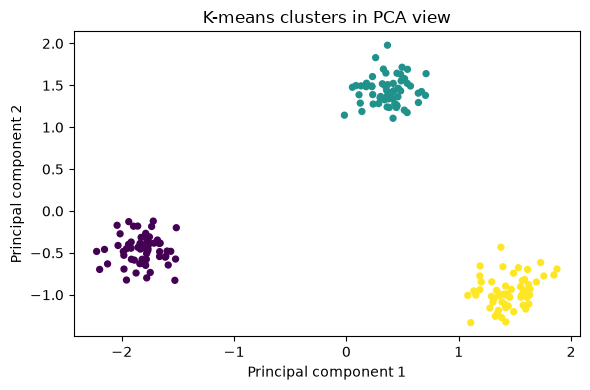

In [4]:
def kmeans(data, k, seed=0, max_iter=100):
    data = np.asarray(data, dtype=float)
    if data.ndim != 2 or not np.isfinite(data).all():
        raise ValueError("Expected a finite 2D feature table")
    if not 1 <= k <= len(data) or max_iter < 1:
        raise ValueError("Invalid k or max_iter")
    rng = np.random.default_rng(seed)
    centers = data[rng.choice(len(data), k, replace=False)].copy()
    previous_labels = None
    history = []
    for _ in range(max_iter):
        squared = ((data[:, None, :] - centers[None, :, :]) ** 2).sum(axis=-1)
        labels = squared.argmin(axis=1)
        history.append(float(squared[np.arange(len(data)), labels].sum()))
        if previous_labels is not None and np.array_equal(labels, previous_labels):
            break
        for group in range(k):
            members = data[labels == group]
            if len(members):
                centers[group] = members.mean(axis=0)
        previous_labels = labels.copy()
    # Reassign after the final update, even when max_iter is reached.
    squared = ((data[:, None, :] - centers[None, :, :]) ** 2).sum(axis=-1)
    labels = squared.argmin(axis=1)
    inertia = float(squared[np.arange(len(data)), labels].sum())
    return centers, labels, inertia, np.array(history + [inertia])

runs = [kmeans(Z, 3, seed=seed) for seed in range(5)]
cluster_centers, labels, inertia, history = min(runs, key=lambda result: result[2])
print("Inertia:", inertia, "cluster sizes:", np.bincount(labels, minlength=3))
assert np.all(np.diff(history) <= 1e-9)
assert labels.shape == (len(Z),)
np.testing.assert_allclose(inertia, np.sum((Z - cluster_centers[labels]) ** 2))
tiny_data = np.array([[0., 0.], [0., 1.], [10., 10.], [10., 11.]])
_, tiny_labels, tiny_inertia, _ = kmeans(tiny_data, 2, seed=0)
assert tiny_labels[0] == tiny_labels[1] and tiny_labels[2] == tiny_labels[3]
assert tiny_labels[0] != tiny_labels[2]
np.testing.assert_allclose(tiny_inertia, 1.)
_, _, duplicate_inertia, _ = kmeans(np.zeros((4, 2)), 3)
assert duplicate_inertia == 0  # exercises empty-cluster handling
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(embedding[:, 0], embedding[:, 1], c=labels, cmap="viridis", s=18)
ax.set(xlabel="Principal component 1", ylabel="Principal component 2", title="K-means clusters in PCA view")
plt.tight_layout()
plt.show()

**Try it:** Compare k=2, 3, and 4. Lower inertia for larger k alone does not prove better clustering.

## Your practice exercises

Use the named answer variables. The checks verify your result; they do not require the same approach as the reference solution. If an assertion fails, read the expected value and inspect your shape and dtype.

### Exercise 1

Reconstruct standardized Z using all PCA components.

In [5]:
full_reconstruction = None  # TODO: replace None with your answer

In [6]:
if full_reconstruction is None:
    print("Pending: complete Exercise 1 first.")
else:
    np.testing.assert_allclose(full_reconstruction, Z, atol=1e-12)
    print("Exercise 1 passed!")

Pending: complete Exercise 1 first.


### Exercise 2

Return one count per cluster, including any empty clusters.

In [7]:
cluster_counts = None  # TODO: replace None with your answer

In [8]:
if cluster_counts is None:
    print("Pending: complete Exercise 2 first.")
else:
    assert cluster_counts.shape == (3,)
    assert cluster_counts.sum() == len(Z)
    np.testing.assert_array_equal(cluster_counts, [(labels == group).sum() for group in range(3)])
    print("Exercise 2 passed!")

Pending: complete Exercise 2 first.


## Independent challenge

Independent deliverable: wrap standardization and PCA in reusable functions, compare k=2–6 across five seeds, plot inertia, and explain a cluster-count choice without assuming the synthetic labels are known. Add tests for constant features, a single cluster, duplicate points, and max_iter=1. Describe at least two limitations: sensitivity to scaling, initialization, non-spherical groups, or outliers.

Add code and explanation cells below. Decide on expected results before checking your implementation.

In [9]:
# Your independent challenge work goes here.

## Before you move on

- Explain the main idea in your own words without reading the examples.
- Make both exercise checks print **passed**.
- Try at least one changed input or edge case and explain the result.
- Finish the independent challenge or write down a specific question to revisit.

Expertise comes from repeated practice and debugging unfamiliar problems. Completing these notebooks gives you a broad practical foundation, not a substitute for that experience.

---

## Reference solutions — try first

These cells use separate reference variables, so they do not fill in your exercise answers. They also check the reference result. Compare your reasoning as well as the output.

### Solution 1

Reconstruct standardized Z using all PCA components.

**Why it works:** All orthonormal principal directions preserve the full feature space, so projecting and projecting back reconstructs Z.

In [10]:
reference_full_reconstruction = (Z @ Vt.T) @ Vt
np.testing.assert_allclose(reference_full_reconstruction, Z, atol=1e-12)
print(reference_full_reconstruction)

[[-1.1351 -0.5949 -0.4598]
 [-0.9165 -0.871  -0.2735]
 [-1.3264 -1.0545 -0.1647]
 [-1.0569 -0.7591 -0.0019]
 [-1.4733 -1.1409  0.171 ]
 [-1.0347 -0.4758  0.106 ]
 [-1.3629 -0.6349 -0.0038]
 [-1.1588 -1.0079 -0.1219]
 [-1.2184 -0.7045 -0.0989]
 [-0.9333 -0.9998 -0.0335]
 [-1.1121 -1.0157 -0.3455]
 [-1.0273 -0.7709 -0.1531]
 [-1.1293 -0.9823 -0.0774]
 [-1.2939 -0.8292  0.0638]
 [-1.2501 -0.712  -0.3177]
 [-1.2417 -1.1044 -0.1414]
 [-1.1813 -0.8976 -0.173 ]
 [-0.9735 -0.6103 -0.352 ]
 [-1.0009 -1.1679 -0.2611]
 [-1.2228 -0.8429 -0.3202]
 [-1.3132 -0.849  -0.2534]
 [-1.2998 -0.7446  0.0535]
 [-1.2041 -0.8594 -0.1261]
 [-1.269  -0.9532 -0.3184]
 [-1.0875 -0.8775 -0.1484]
 [-1.1612 -0.7686  0.1459]
 [-1.2393 -0.9337 -0.0846]
 [-1.3334 -0.6372  0.0525]
 [-1.08   -0.8838  0.0172]
 [-1.0213 -0.774  -0.1753]
 [-1.4717 -0.6948 -0.1891]
 [-1.3331 -0.7048 -0.0586]
 [-1.4278 -0.8801 -0.1733]
 [-1.0308 -1.1984 -0.1952]
 [-1.217  -0.6112 -0.327 ]
 [-1.6784 -1.1078 -0.0728]
 [-1.0609 -0.5555 -0.0467]
 

### Solution 2

Return one count per cluster, including any empty clusters.

**Why it works:** bincount counts observations assigned to each nonnegative label. minlength retains slots for empty clusters.

In [11]:
reference_cluster_counts = np.bincount(labels, minlength=3)
assert reference_cluster_counts.shape == (3,)
assert reference_cluster_counts.sum() == len(Z)
np.testing.assert_array_equal(reference_cluster_counts, [(labels == group).sum() for group in range(3)])
print(reference_cluster_counts)

[60 60 60]


## Continue learning

- [Official NumPy documentation: numpy.linalg.svd ](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)
- [Official NumPy documentation: basics.broadcasting ](https://numpy.org/doc/stable/user/basics.broadcasting.html)